In [1]:
import cv2
import csv
import os
import math
import torch
import numpy as np
from collections import defaultdict
from ultralytics import YOLO, RTDETR
import easyocr

# True: evalúa RT-DETR
USAR_RTDETR = True

# Configuración del rastreador para que borre objetos rápido cuando salgan de la pantalla
TRACKER_CFG = 'bytetrack_rapido.yaml'
with open(TRACKER_CFG, 'w') as f:
    f.write("""
tracker_type: bytetrack
track_high_thresh: 0.35
track_low_thresh: 0.1
new_track_thresh: 0.4
track_buffer: 8
match_thresh: 0.8
fuse_score: True
""".strip())

# Rutas de los archivos de entrada, salida y selección de tarjeta gráfica o procesador
VIDEO_ENTRADA = 'C0142.MP4'

# Nombres de salida dinámicos para evitar sobreescritura entre YOLO y RT-DETR
SUFIJO_MODELO = '_rtdetr' if USAR_RTDETR else '_yolo'
VIDEO_SALIDA = f'resultado_C0142{SUFIJO_MODELO}.mp4'
CSV_SALIDA = f'detecciones_seguimiento{SUFIJO_MODELO}.csv'

MODELO_GENERAL_PATH = 'yolo11n.pt'
MODELO_MATRICULAS_PATH = 'best_rtdetr.pt' if USAR_RTDETR else 'best.pt'

# Clases que nos interesan: personas y diferentes tipos de vehículos
CLASES_INTERES = [0, 2, 3, 5, 7]
CLASES_VEHICULOS = [2, 3, 5, 7]

DISPOSITIVO = 0 if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo asignado: {DISPOSITIVO}")
print(f"Configuración activa: {'RT-DETR' if USAR_RTDETR else 'YOLO'}")
print(f"Vídeo de salida: {VIDEO_SALIDA}")
print(f"CSV de salida:   {CSV_SALIDA}")

# Carga del detector general y selección condicional del detector de matrículas
modelo_general = YOLO(MODELO_GENERAL_PATH)

if USAR_RTDETR:
    print(f"Cargando detector de matrículas RT-DETR ({MODELO_MATRICULAS_PATH})...")
    modelo_matriculas = RTDETR(MODELO_MATRICULAS_PATH)
else:
    print(f"Cargando detector de matrículas YOLO ({MODELO_MATRICULAS_PATH})...")
    modelo_matriculas = YOLO(MODELO_MATRICULAS_PATH)

# Preparación del lector de texto para las placas
print("Cargando EasyOCR...")
reader_ocr = easyocr.Reader(['es', 'en'], gpu=torch.cuda.is_available())

# Abrir el vídeo original y preparar el nuevo vídeo con los dibujos
cap = cv2.VideoCapture(VIDEO_ENTRADA)
if not cap.isOpened():
    raise FileNotFoundError(f"No se pudo abrir el video: {VIDEO_ENTRADA}")

ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
fps_salida = fps if fps > 0 else 25.0
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

out = cv2.VideoWriter(
    VIDEO_SALIDA,
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps_salida,
    (ancho, alto)
)

# Crear el archivo CSV y escribir los nombres de las columnas
f_csv = open(CSV_SALIDA, mode='w', newline='', encoding='utf-8')
csv_writer = csv.writer(f_csv)

csv_writer.writerow([
    'fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking',
    'x1', 'y1', 'x2', 'y2',
    'matricula_en_su_caso', 'confianza_matricula',
    'mx1', 'my1', 'mx2', 'my2', 'texto_matricula'
])

# Filtros para evitar contar coches aparcados o detecciones que duren solo un instante
MIN_FRAMES_VALIDO = 10
MIN_DESPLAZAMIENTO = 40

# Historial para saber cuánto se mueve cada objeto y qué clase es la más votada
historial_tracks = defaultdict(lambda: {
    'inicio': None,
    'actual': None,
    'frames': 0,
    'clases': defaultdict(int)
})

# Conjuntos para registrar los identificadores únicos y no repetir el conteo
conteo_unicos = {
    'person': set(),
    'car': set(),
    'motorcycle': set(),
    'bus': set(),
    'truck': set()
}

# Memoria temporal para no repetir la lectura de matrícula en cada fotograma
cache_matriculas = {}

# Colores para dibujar las cajas según la clase
COLORES = {
    'person': (255, 105, 65),
    'car': (40, 200, 40),
    'motorcycle': (0, 165, 255),
    'bus': (200, 200, 0),
    'truck': (180, 0, 180),
    'matricula': (0, 255, 255)
}

print(f"Procesando {total_frames} fotogramas...")

# Procesar el vídeo fotograma a fotograma
frame_idx = 0
with torch.no_grad():
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
       
        frame_idx += 1

        # Detectar y seguir a personas y vehículos en la escena
        resultados_track = modelo_general.track(
            source=frame,
            persist=True,
            classes=CLASES_INTERES,
            tracker=TRACKER_CFG,
            conf=0.35,
            imgsz=640,
            device=DISPOSITIVO,
            verbose=False
        )

        if resultados_track and len(resultados_track) > 0 and resultados_track[0].boxes is not None:
            cajas = resultados_track[0].boxes

            for box in cajas:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                confianza = float(box.conf[0])
                clase_id = int(box.cls[0])
                nombre_clase = modelo_general.names[clase_id]
                track_id = int(box.id[0]) if box.id is not None else -1

                # Descartar detecciones diminutas en el fondo
                w_box = x2 - x1
                h_box = y2 - y1
                if w_box < 25 or h_box < 25:
                    continue

                cx = int((x1 + x2) / 2)
                cy = int((y1 + y2) / 2)

                # Comprobar la trayectoria del objeto y validar si debe sumarse al total
                clase_dominante = nombre_clase
                if track_id != -1:
                    t = historial_tracks[track_id]
                    t['frames'] += 1
                    t['clases'][nombre_clase] += 1
                    if t['inicio'] is None:
                        t['inicio'] = (cx, cy)
                    t['actual'] = (cx, cy)

                    # Quedarnos con la clase que más veces haya salido
                    clase_dominante = max(t['clases'].items(), key=lambda x: x[1])[0]

                    # Validar si el objeto estuvo el tiempo mínimo y se movió lo suficiente
                    if t['frames'] >= MIN_FRAMES_VALIDO:
                        disp = math.hypot(t['actual'][0] - t['inicio'][0], t['actual'][1] - t['inicio'][1])
                        es_vehiculo = clase_id in CLASES_VEHICULOS
                       
                        if (not es_vehiculo and disp >= 20) or (es_vehiculo and disp >= MIN_DESPLAZAMIENTO):
                            for c in conteo_unicos:
                                conteo_unicos[c].discard(track_id)
                            if clase_dominante in conteo_unicos:
                                conteo_unicos[clase_dominante].add(track_id)

                caja_matricula = None
                conf_matricula = None
                texto_matricula = ""

                # Buscar la matrícula si el objeto es un vehículo
                if clase_id in CLASES_VEHICULOS:
                    vx1, vy1 = max(0, x1), max(0, y1)
                    vx2, vy2 = min(ancho, x2), min(alto, y2)
                    w_veh = vx2 - vx1
                    h_veh = vy2 - vy1

                    # Ignorar vehículos que ya estén cortados saliendo de la pantalla
                    esta_saliendo = (vx1 <= 15) or (vx2 >= ancho - 15)

                    if w_veh > 50 and h_veh > 50 and not esta_saliendo:
                        usar_detector = True

                        # Reutilizar la posición guardada de la matrícula si pasaron pocos fotogramas
                        if track_id != -1 and track_id in cache_matriculas:
                            frames_pasados = frame_idx - cache_matriculas[track_id]['frame']
                            if frames_pasados <= 4:
                                rx1, ry1, rx2, ry2 = cache_matriculas[track_id]['rel_coords']
                                gx1 = int(vx1 + rx1 * w_veh)
                                gy1 = int(vy1 + ry1 * h_veh)
                                gx2 = int(vx1 + rx2 * w_veh)
                                gy2 = int(vy1 + ry2 * h_veh)
                                caja_matricula = (gx1, gy1, gx2, gy2)
                               
                                conf_matricula = cache_matriculas[track_id].get('conf', 0.0)
                                texto_matricula = cache_matriculas[track_id].get('texto', "")
                                usar_detector = False

                        # Ejecutar el modelo de matrículas en el recorte del coche
                        if usar_detector:
                            roi_vehiculo = frame[vy1:vy2, vx1:vx2]
                            res_placas = modelo_matriculas(
                                roi_vehiculo,
                                imgsz=320,
                                conf=0.35,
                                device=DISPOSITIVO,
                                verbose=False
                            )

                            if res_placas and len(res_placas) > 0 and len(res_placas[0].boxes) > 0:
                                mejor_placa = res_placas[0].boxes[0]
                                px1_r, py1_r, px2_r, py2_r = map(int, mejor_placa.xyxy[0].tolist())
                               
                                gx1 = vx1 + px1_r
                                gy1 = vy1 + py1_r
                                gx2 = vx1 + px2_r
                                gy2 = vy1 + py2_r
                                caja_matricula = (gx1, gy1, gx2, gy2)
                                conf_matricula = float(mejor_placa.conf[0])

                                # Recortar y preparar la placa para leer su texto
                                img_placa = frame[gy1:gy2, gx1:gx2]
                                if img_placa.shape[0] > 10 and img_placa.shape[1] > 20:
                                   
                                    # Agrandar la imagen y pasar a grises para ver mejor los caracteres
                                    img_ampliada = cv2.resize(img_placa, None, fx=2.5, fy=2.5, interpolation=cv2.INTER_CUBIC)
                                    img_gris = cv2.cvtColor(img_ampliada, cv2.COLOR_BGR2GRAY)

                                    # Leer letras y números con EasyOCR
                                    resultados_ocr = reader_ocr.readtext(img_gris, detail=0, paragraph=True)
                                   
                                    if resultados_ocr:
                                        texto_crudo = "".join(resultados_ocr).upper()
                                        texto_limpio = "".join(filter(str.isalnum, texto_crudo))
                                       
                                        # Guardar solo si tiene una longitud lógica de matrícula
                                        if len(texto_limpio) >= 4:
                                            texto_matricula = texto_limpio

                                # Guardar la matrícula en memoria para los siguientes cuadros
                                if track_id != -1:
                                    cache_matriculas[track_id] = {
                                        'rel_coords': (px1_r / w_veh, py1_r / h_veh, px2_r / w_veh, py2_r / h_veh),
                                        'frame': frame_idx,
                                        'conf': conf_matricula,
                                        'texto': texto_matricula
                                    }
                    else:
                        # Si el coche toca el borde, borrar la matrícula de la memoria
                        if track_id != -1:
                            cache_matriculas.pop(track_id, None)

                # Guardar todos los datos calculados en la fila del CSV
                tiene_mat = "Si" if caja_matricula is not None else "No"
                conf_mat_str = f"{conf_matricula:.2f}" if caja_matricula is not None and conf_matricula is not None else ""
                mx1, my1, mx2, my2 = caja_matricula if caja_matricula is not None else ("", "", "", "")

                csv_writer.writerow([
                    frame_idx, clase_dominante, f"{confianza:.2f}", track_id,
                    x1, y1, x2, y2, tiene_mat, conf_mat_str,
                    mx1, my1, mx2, my2, texto_matricula
                ])

                # Dibujar la caja y etiqueta del vehículo o persona
                color_obj = COLORES.get(clase_dominante, (0, 255, 0))
                cv2.rectangle(frame, (x1, y1), (x2, y2), color_obj, 2)
                cv2.putText(
                    frame,
                    f"ID:{track_id} {clase_dominante}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_obj, 2
                )

                # Dibujar la caja amarilla y el texto de la matrícula si existe
                if caja_matricula is not None:
                    cv2.rectangle(frame, (mx1, my1), (mx2, my2), COLORES['matricula'], 2)
                    etiqueta_placa = f"{texto_matricula} ({conf_mat_str})" if texto_matricula else "Matricula"
                    cv2.putText(
                        frame, etiqueta_placa,
                        (mx1, max(15, my1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, COLORES['matricula'], 2
                    )

        # Panel informativo en la esquina superior con los conteos acumulados
        cv2.rectangle(frame, (15, 15), (270, 160), (0, 0, 0), -1)
        cv2.rectangle(frame, (15, 15), (270, 160), (255, 255, 255), 1)
        cv2.putText(frame, f"Frame: {frame_idx}/{total_frames}", (25, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (255, 255, 255), 1)

        y_offset = 62
        for clase, ids in conteo_unicos.items():
            color_txt = COLORES.get(clase, (200, 200, 200))
            cv2.putText(frame, f"Total {clase}s: {len(ids)}", (25, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_txt, 1)
            y_offset += 22

        # Grabar el fotograma con los dibujos en el vídeo final
        out.write(frame)
        if frame_idx % 50 == 0 or frame_idx == total_frames:
            print(f"Progreso: {frame_idx}/{total_frames} fotogramas procesados...")

# Cerrar el vídeo, el archivo de datos y mostrar confirmación final
cap.release()
out.release()
f_csv.close()

print(f"\n¡Procesamiento finalizado con éxito ({'RT-DETR' if USAR_RTDETR else 'YOLO'})!")
print(f"Vídeo generado: {VIDEO_SALIDA}")
print(f"CSV generado:   {CSV_SALIDA}")

Dispositivo asignado: cpu
Configuración activa: RT-DETR
Vídeo de salida: resultado_C0142_rtdetr.mp4
CSV de salida:   detecciones_seguimiento_rtdetr.csv
Cargando detector de matrículas RT-DETR (best_rtdetr.pt)...


Using CPU. Note: This module is much faster with a GPU.


Cargando EasyOCR...
Procesando 2832 fotogramas...
Progreso: 50/2832 fotogramas procesados...
Progreso: 100/2832 fotogramas procesados...
Progreso: 150/2832 fotogramas procesados...
Progreso: 200/2832 fotogramas procesados...
Progreso: 250/2832 fotogramas procesados...
Progreso: 300/2832 fotogramas procesados...
Progreso: 350/2832 fotogramas procesados...
Progreso: 400/2832 fotogramas procesados...
Progreso: 450/2832 fotogramas procesados...
Progreso: 500/2832 fotogramas procesados...
Progreso: 550/2832 fotogramas procesados...
Progreso: 600/2832 fotogramas procesados...
Progreso: 650/2832 fotogramas procesados...
Progreso: 700/2832 fotogramas procesados...
Progreso: 750/2832 fotogramas procesados...


c:\Users\Nico\anaconda3\envs\VC_P4\lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Progreso: 800/2832 fotogramas procesados...
Progreso: 850/2832 fotogramas procesados...
Progreso: 900/2832 fotogramas procesados...
Progreso: 950/2832 fotogramas procesados...
Progreso: 1000/2832 fotogramas procesados...
Progreso: 1050/2832 fotogramas procesados...
Progreso: 1100/2832 fotogramas procesados...
Progreso: 1150/2832 fotogramas procesados...
Progreso: 1200/2832 fotogramas procesados...
Progreso: 1250/2832 fotogramas procesados...
Progreso: 1300/2832 fotogramas procesados...
Progreso: 1350/2832 fotogramas procesados...
Progreso: 1400/2832 fotogramas procesados...
Progreso: 1450/2832 fotogramas procesados...
Progreso: 1500/2832 fotogramas procesados...
Progreso: 1550/2832 fotogramas procesados...
Progreso: 1600/2832 fotogramas procesados...
Progreso: 1650/2832 fotogramas procesados...
Progreso: 1700/2832 fotogramas procesados...
Progreso: 1750/2832 fotogramas procesados...
Progreso: 1800/2832 fotogramas procesados...
Progreso: 1850/2832 fotogramas procesados...
Progreso: 1900

Using CPU. Note: This module is much faster with a GPU.


Cargando modelo clásico (EasyOCR)...
Cargando modelo VLM avanzado (Florence-2)...

Iniciando el experimento...
---------------------------
Examinando la foto: 0019GVM.jpg


c:\Users\Nico\anaconda3\envs\VC_P4\lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
c:\Users\Nico\anaconda3\envs\VC_P4\lib\site-packages\transformers\generation\configuration_utils.py:453: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(


Examinando la foto: 0083CPC.jpg
Examinando la foto: 0239GLK.jpg
Examinando la foto: 0310RCU.jpg
Examinando la foto: 0478LFR.jpg
Examinando la foto: 0523HNF.jpg
Examinando la foto: 0635LYZ.jpg
Examinando la foto: 0674BZH.jpg
Examinando la foto: 0802HFP.jpg
Examinando la foto: 0849GSD.jpg
Examinando la foto: 1049LDV.jpg
Examinando la foto: 1104CZK.jpg
Examinando la foto: 1159FPG.jpg
Examinando la foto: 1268CDN.jpg
Examinando la foto: 1319FSX.jpg
Examinando la foto: 1336LFG.jpg
Examinando la foto: 2021AXP.jpg
Examinando la foto: 220LNW.jpg
Examinando la foto: 2496BMT.jpg
Examinando la foto: 2711LKN.jpg
Examinando la foto: 2942HFB.jpg
Examinando la foto: 3027LMJ.jpg
Examinando la foto: 3685HDP.jpg
Examinando la foto: 3821GYG.jpg
Examinando la foto: 3838KWB.jpg
Examinando la foto: 4041LHK.jpg
Examinando la foto: 4078BVX.jpg
Examinando la foto: 4103HMX.jpg
Examinando la foto: 4138KFK.jpg
Examinando la foto: 4324KRD.jpg
Examinando la foto: 4511THT.jpg
Examinando la foto: 4577JNF.jpg
Examinand

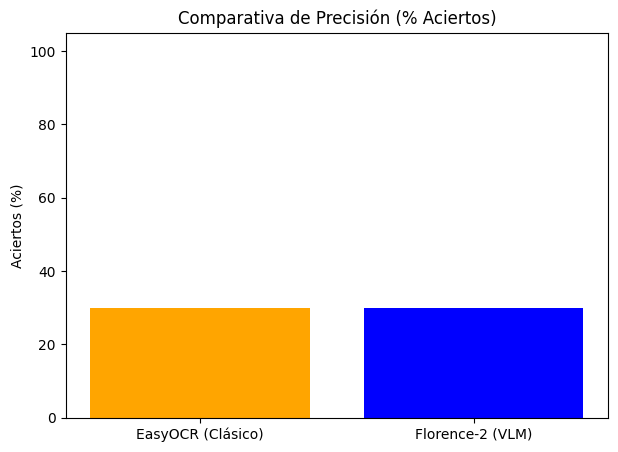

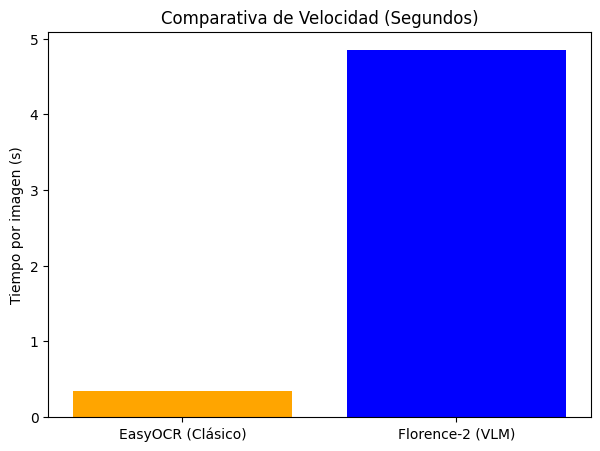

In [3]:
import sys
import types
import importlib.machinery

# Creamos un módulo falso pero con los identificadores oficiales que exige Python
fake_flash = types.ModuleType('flash_attn')
fake_flash.__spec__ = importlib.machinery.ModuleSpec('flash_attn', None)

sys.modules['flash_attn'] = fake_flash
sys.modules['flash_attn.bert_padding'] = fake_flash

import os
import time
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch
import easyocr
from transformers import AutoProcessor, AutoModelForCausalLM
from PIL import Image

# 1. CARPETA DONDE ESTÁN TUS FOTOS DE PRUEBA
IMAGE_FOLDER = "./fotos_prueba" 
CSV_OUTPUT = "resultados_comparativa.csv"

# 2. CARGAMOS EL MODELO CLÁSICO (EasyOCR)
print("Cargando modelo clásico (EasyOCR)...")
reader_ocr = easyocr.Reader(['es', 'en'], gpu=torch.cuda.is_available())

# 3. CARGAMOS LA INTELIGENCIA ARTIFICIAL (Florence-2, modelo VLM recomendado)
print("Cargando modelo VLM avanzado (Florence-2)...")
device = "cuda:0" if torch.cuda.is_available() else "cpu"
torch_dtype = torch.float16 if torch.cuda.is_available() else torch.float32

# Descarga automáticamente el modelo de HuggingFace la primera vez
processor = AutoProcessor.from_pretrained("microsoft/Florence-2-base", trust_remote_code=True)
model_vlm = AutoModelForCausalLM.from_pretrained("microsoft/Florence-2-base", torch_dtype=torch_dtype, trust_remote_code=True).to(device)

all_results = []

if not os.path.exists(IMAGE_FOLDER):
    print(f"ERROR: No existe la carpeta {IMAGE_FOLDER}")
    exit()

print("\nIniciando el experimento...\n---------------------------")

# 4. BUCLE: LEER CADA FOTO CON LOS DOS MODELOS
for file_name in os.listdir(IMAGE_FOLDER):
    if not file_name.lower().endswith(('.jpg', '.png', '.jpeg')):
        continue
    
    # El nombre de la foto es la matricula de verdad (Ej: 1234ABC.jpg -> 1234ABC)
    matricula_real = file_name.split('.')[0].upper()
    img_path = os.path.join(IMAGE_FOLDER, file_name)
    
    # Leemos la foto de dos maneras (OpenCV para EasyOCR, y PIL para Florence)
    img_cv = cv2.imread(img_path)
    img_pil = Image.open(img_path).convert("RGB")

    print(f"Examinando la foto: {file_name}")

    # -------- PRUEBA 1: EasyOCR --------
    start_time = time.time()
    ocr_result = reader_ocr.readtext(img_cv, detail=0, paragraph=True)
    time_easy = time.time() - start_time
    
    texto_easy = "".join(ocr_result).upper()
    texto_easy = "".join(filter(str.isalnum, texto_easy))

    # -------- PRUEBA 2: Florence-2 (VLM) --------
    start_time = time.time()
    prompt = "<OCR>"
    inputs = processor(text=prompt, images=img_pil, return_tensors="pt").to(device, torch_dtype)
    
    with torch.no_grad():
        generated_ids = model_vlm.generate(
            input_ids=inputs["input_ids"],
            pixel_values=inputs["pixel_values"],
            max_new_tokens=64,
            do_sample=False,
            num_beams=1
        )
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
    time_vlm = time.time() - start_time
    
    texto_vlm_crudo = processor.post_process_generation(generated_text, task=prompt, image_size=(img_pil.width, img_pil.height))
    texto_vlm = texto_vlm_crudo[prompt].upper().replace(" ", "")
    texto_vlm = "".join(filter(str.isalnum, texto_vlm))

    # Guardar resultados de este asalto
    all_results.append({
        'imagen': file_name,
        'matricula_real': matricula_real,
        'easyocr_texto': texto_easy,
        'easyocr_tiempo': time_easy,
        'vlm_texto': texto_vlm,
        'vlm_tiempo': time_vlm
    })

# 5. CALCULAR QUIÉN GANÓ Y HACER LAS GRÁFICAS
df = pd.DataFrame(all_results)
df.to_csv(CSV_OUTPUT, index=False)

total_imgs = len(df)
if total_imgs == 0:
    print("No había imágenes para analizar.")
    exit()

# Contamos cuántas veces cada modelo adivinó la matrícula idéntica al nombre del archivo
df['acierto_easyocr'] = df['easyocr_texto'] == df['matricula_real']
df['acierto_vlm'] = df['vlm_texto'] == df['matricula_real']

precision_easy = (df['acierto_easyocr'].sum() / total_imgs) * 100
precision_vlm = (df['acierto_vlm'].sum() / total_imgs) * 100

tiempo_medio_easy = df['easyocr_tiempo'].mean()
tiempo_medio_vlm = df['vlm_tiempo'].mean()

print("\n=== RESUMEN FINAL DEL EXPERIMENTO ===")
print(f"Imágenes analizadas: {total_imgs}")
print(f"EasyOCR -> Precisión: {precision_easy:.2f}% | Tiempo por foto: {tiempo_medio_easy:.4f} s")
print(f"Florence2 -> Precisión: {precision_vlm:.2f}% | Tiempo por foto: {tiempo_medio_vlm:.4f} s")

# Dibujar Gráfica 1: Precisión
modelos = ['EasyOCR (Clásico)', 'Florence-2 (VLM)']
plt.figure(figsize=(7, 5))
plt.bar(modelos, [precision_easy, precision_vlm], color=['orange', 'blue'])
plt.title('Comparativa de Precisión (% Aciertos)')
plt.ylabel('Aciertos (%)')
plt.ylim(0, 105)
plt.savefig('grafica_precision.png')

# Dibujar Gráfica 2: Tiempo
plt.figure(figsize=(7, 5))
plt.bar(modelos, [tiempo_medio_easy, tiempo_medio_vlm], color=['orange', 'blue'])
plt.title('Comparativa de Velocidad (Segundos)')
plt.ylabel('Tiempo por imagen (s)')
plt.savefig('grafica_tiempo.png')

print("¡Experimento terminado! Las gráficas se han guardado como 'grafica_precision.png' y 'grafica_tiempo.png'.")